# BEVPlace++ on KITTI: experiments

Runtime -> Change runtime type -> **T4 GPU** (or better). Set cell 1, then **Runtime -> Run all**.
`MODE` in cell 1 says what this run is for (train / eval / smoke); every cell does only what that mode needs.

- **BEV variant**: built on the Azure VM (`METHOD=bev bash scripts/azure_build.sh`), saved in `MyDrive/lpr/bev/<variant>/`.
- **Run**: `MyDrive/lpr/runs/bev/<run>/` (`config.json`, `metrics.csv`, a checkpoint per epoch).
- **Official checkpoint** (`EVAL_OFFICIAL`): the authors' network evaluated on our BEV images, in `MyDrive/lpr/runs/bev/official_<variant>/`.
- **Evaluations** (`EVALS`, types in `src/lpr/evals.py`): `<run>/eval/<type>/<checkpoint>/`; tables in
  `MyDrive/lpr/runs_summary.csv` and `MyDrive/lpr/evals_summary.csv`.

## 1. Settings

In [1]:
REPO_URL = "https://github.com/dov85/lidar-place-recognition"
DRIVE = "/content/drive/MyDrive/lpr"
SEQ = "00"                          # training sequence
# What this run of the notebook does. "Runtime -> Run all" works in every mode:
#   "train": data, training (a new run, or the continuation of an unfinished one; a finished run
#            is not trained again), then the evaluations
#   "eval":  only the evaluations of an existing run (nothing is trained or built)
#   "smoke": a short training test (time and GPU memory), nothing is saved to Drive
MODE = "train"
EVAL_CKPT = "last"                  # "last" or a checkpoint file of the run, e.g. "epoch_18.pth"
EVALS = ['seqs_heading', 'compass']   # types in src/lpr/evals.py (EVAL_TYPES)
EVAL_OFFICIAL = True                # also evaluate the authors' checkpoint (once; then it is skipped)
CHECK_BEV = False                   # compare our BEV images with the official script on 3 scans

# BEV variant: only what differs from the defaults (src/lpr/experiments.py, BEV_DEFAULTS):
#   half_size=40.0, z_abs=40.0, voxel=0.4, res=0.4, max_count=10, ground="none"
BEV_TAG = ""          # name for a changed variant; empty = date + hash
BEV_PARAMS = dict()                 # e.g. dict(ground="patchwork")

# Training run: only what differs from the defaults (BEV_TRAIN_DEFAULTS, the official values):
#   train_frames=3000, pos_thr=5.0, neg_thr=7.0, epochs=40, lr=1e-4, batch=4, negatives=10,
#   margin=0.3, rot_aug=True, seed=1024,
#   arch="rein"   ("plain": the same CNN + NetVLAD in one pass, without REIN's 8 rotations, i.e. no
#                  built-in rotation invariance; with rot_aug=True/False for with/without rotated images)
RUN_TAG = "without_Rein"          # name for a changed run; empty = date + hash
TRAIN_PARAMS = dict(epochs=20,rot_aug=False,arch="plain")               # e.g. dict(epochs=20)

KITTI = "/content/kitti"            # poses (and a few raw scans for CHECK_BEV)

## 2. Drive, GPU, code, poses, Drive layout

In [2]:
from google.colab import drive, userdata
drive.mount('/content/drive')
import os, sys, json, subprocess, importlib, glob
assert MODE in ("train", "eval", "smoke"), MODE
os.makedirs(DRIVE, exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

url = REPO_URL
try:  # private repo: store a token in Colab Secrets as GITHUB_TOKEN
    url = REPO_URL.replace("https://", f"https://{userdata.get('GITHUB_TOKEN')}@")
except Exception:
    pass
if not os.path.exists("/content/lpr"):
    subprocess.run(["git", "clone", "-q", url, "/content/lpr"], check=True)
else:
    subprocess.run(["git", "-C", "/content/lpr", "pull", "-q"], check=True)
%cd /content/lpr
!git log --oneline -1
!bash scripts/setup_third_party.sh
!pip install -q -r requirements.txt faiss-cpu

sys.path.insert(0, "/content/lpr/src")
import lpr.experiments as ex, lpr.evals as ev
importlib.reload(ex); importlib.reload(ev)
missing_poses = [s for s in ev.ALL_SEQS if not os.path.exists(f"{KITTI}/poses/{s}.txt")]
if missing_poses:
    !python scripts/download_kitti.py --out {KITTI} --seqs {" ".join(missing_poses)} --poses_only

# older results into the current Drive layout (does nothing once done)
if os.path.exists(f"{DRIVE}/runs/ndt_kitti00"):
    !python scripts/migrate_stage1.py --drive {DRIVE} --apply
!python scripts/migrate_layout.py --drive {DRIVE} --apply

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
Tesla T4, 15360 MiB
/content/lpr
ff670d5 (HEAD -> main, origin/main, origin/HEAD) Created using Colab
third_party/NDT-Transformer @ 51f90df
third_party/BEVPlace2 @ 2d0636d5
nothing to migrate


## 3. Names of the BEV variant and the run

In [3]:
VARIANT, BEV_FULL, bev_exists = ex.resolve_variant(DRIVE, "bev", BEV_PARAMS, BEV_TAG)
VDIR = f"{DRIVE}/bev/{VARIANT}"         # permanent copy on Drive
BEV = f"/content/bev/{VARIANT}"         # working copy on this machine

RUN, TRAIN_FULL, run_state = ex.resolve_run(DRIVE, dict(TRAIN_PARAMS, seq=SEQ), VARIANT, RUN_TAG, method="bev")
RUN_DIR = f"{DRIVE}/runs/bev/{RUN}"
print("mode:       ", MODE)
print("BEV variant:", VARIANT, "(on Drive)" if bev_exists else "(new: build it on Azure, see below)")
print(json.dumps(BEV_FULL))
print("run:        ", RUN, f"({run_state})")
print(json.dumps(TRAIN_FULL))
if MODE == "eval" and run_state == "new":
    print("MODE = 'eval' and no run with these parameters: only the official checkpoint is evaluated")
defaults = ex.BEV_DEFAULTS
args = " ".join(f"--{k} {v}" for k, v in BEV_FULL.items() if v != defaults[k])
print("\nTo build the variant on the Azure VM (inside tmux, in the repository folder):")
print(f'  git pull && METHOD=bev VARIANT={VARIANT}' + (f' ARGS="{args}"' if args else "") +
      ' bash scripts/azure_build.sh "<SAS URL>"')

t = TRAIN_FULL
train_args = (f"--bev_dir {BEV} --kitti_root {KITTI} --bev_variant {VARIANT} --seq {t['seq']} "
              f"--train_frames {t['train_frames']} --pos_thr {t['pos_thr']} --neg_thr {t['neg_thr']} "
              f"--epochs {t['epochs']} --lr {t['lr']} --batch {t['batch']} --negatives {t['negatives']} "
              f"--margin {t['margin']} --seed {t['seed']}" + ("" if t["rot_aug"] else " --no_rot_aug")
              + (f" --arch {t['arch']}" if t["arch"] != "rein" else ""))

mode:        train
BEV variant: 2026-10-05_baseline_7711ab (on Drive)
{"half_size": 40.0, "z_abs": 40.0, "voxel": 0.4, "res": 0.4, "max_count": 10, "ground": "none"}
run:         2026-10-08_without_Rein_b14094 (resume)
{"seq": "00", "train_frames": 3000, "pos_thr": 5.0, "neg_thr": 7.0, "epochs": 20, "lr": 0.0001, "batch": 4, "negatives": 10, "margin": 0.3, "rot_aug": false, "seed": 1024, "arch": "plain"}

To build the variant on the Azure VM (inside tmux, in the repository folder):
  git pull && METHOD=bev VARIANT=2026-10-05_baseline_7711ab bash scripts/azure_build.sh "<SAS URL>"


## 4. BEV images: from Azure to Drive to this machine
Copies the tars of the variant from the blob container (SAS URL in Colab Secrets as `AZURE_SAS`, permissions read + list)
into `VDIR`, then unpacks them into `BEV`. Training needs sequence 00, the evaluations every sequence.

In [4]:
need = [SEQ] if MODE == "smoke" else ev.ALL_SEQS
tar_of = lambda s: f"{VDIR}/{ex.archive_name('bev', s)}"
missing = [s for s in need if not os.path.exists(tar_of(s))]
if missing:
    res = subprocess.run(["python", "scripts/fetch_from_azure.py", "--sas_url", userdata.get("AZURE_SAS"), "--method", "bev",
                          "--variant", VARIANT, "--seqs", *missing, "--drive", DRIVE],
                         capture_output=True, text=True, cwd="/content/lpr")
    print(res.stdout, res.stderr[-2000:])
for s in need:
    if os.path.exists(tar_of(s)) and not os.path.exists(f"{BEV}/{s}/000000.png"):
        os.makedirs(BEV, exist_ok=True)
        subprocess.run(["tar", "-xf", tar_of(s), "-C", BEV], check=True)
HAVE = [s for s in need if os.path.exists(f"{BEV}/{s}/000000.png")]
print("BEV images on this machine for:", {s: len(os.listdir(f"{BEV}/{s}")) for s in HAVE})
if MODE in ("train", "smoke") and SEQ not in HAVE:
    raise SystemExit(f"sequence {SEQ} missing: build the variant on Azure first (command printed in cell 3)")

BEV images on this machine for: {'00': 4541, '02': 4661, '05': 2761, '06': 1101, '08': 4071}


### 4b. Optional (`CHECK_BEV = True`): our BEV images = the official script's
Downloads 3 scans of sequence 00 and compares `lpr.bev` with `third_party/BEVPlace2/datasets/gen_bev_images.py`
pixel by pixel. Expected last line: `IDENTICAL`.

In [5]:
if CHECK_BEV:
    !pip install -q open3d
    !python scripts/download_kitti.py --out /content/kitti_check --seqs 00 --first 3
    scans = " ".join(f"/content/kitti_check/sequences/00/velodyne/{i:06d}.bin" for i in range(3))
    !python tests/test_bev_matches_official.py --scans {scans}
else:
    print("skipped (CHECK_BEV = False)")

skipped (CHECK_BEV = False)


## 5. Smoke test (MODE = "smoke"): 20 iterations
Seconds per iteration x 750 is roughly one epoch, plus the descriptor cache at the start of each epoch.
If 4 x 12 images do not fit in GPU memory, training switches to one tuple per forward pass (`split_forward`).

In [6]:
if MODE == "smoke":
    !rm -rf /content/smoke
    !python scripts/train_bev_kitti.py {train_args} --log_dir /content/smoke --epochs 1 --max_iters 20 --eval_every 0 2>&1 | grep -v Warning
else:
    print("skipped (MODE =", MODE + ")")

skipped (MODE = train)


## 6. Training (MODE = "train"; continues an unfinished run, also inside an epoch)

In [7]:
if MODE == "train":
    print("run:", RUN_DIR, f"({run_state})")
    !python scripts/train_bev_kitti.py {train_args} --log_dir {RUN_DIR} 2>&1 | grep -v Warning
else:
    print("skipped (MODE =", MODE + ")")

run: /content/drive/MyDrive/lpr/runs/bev/2026-10-08_without_Rein_b14094 (resume)
  warnings.warn(
  warnings.warn(msg)
network: plain (1 rotation(s) per image)
resumed from /content/drive/MyDrive/lpr/runs/bev/2026-10-08_without_Rein_b14094/latest.pth: epoch 1, iteration 0
device cuda, parameters 1.36 M, training frames 3000, images 4541
epoch 2: descriptor cache for hard mining
epoch 2 it 50/750 loss 0.0845 0.70s/it (~8 min left in epoch) peak GPU mem 6.9 GB
epoch 2 it 100/750 loss 0.0825 0.68s/it (~7 min left in epoch) peak GPU mem 6.9 GB
epoch 2 it 150/750 loss 0.0786 0.67s/it (~7 min left in epoch) peak GPU mem 6.9 GB
epoch 2 it 200/750 loss 0.0855 0.69s/it (~6 min left in epoch) peak GPU mem 6.9 GB
epoch 2 it 250/750 loss 0.0729 0.69s/it (~6 min left in epoch) peak GPU mem 6.9 GB
epoch 2 it 300/750 loss 0.0580 0.68s/it (~5 min left in epoch) peak GPU mem 6.9 GB
epoch 2 it 350/750 loss 0.0705 0.69s/it (~5 min left in epoch) peak GPU mem 6.9 GB
epoch 2 it 400/750 loss 0.0686 0.69s/it

## 7. Evaluations (`EVALS`, checkpoint `EVAL_CKPT`; the official checkpoint with `EVAL_OFFICIAL`)
Each type is stored in `<run>/eval/<type>/<checkpoint>/` and is not repeated once complete.

seqs_heading | 2026-10-08_without_Rein_b14094 | epoch_20
  00: evaluating
  02: evaluating
  05: evaluating
  06: evaluating
  08: evaluating
  -> /content/drive/MyDrive/lpr/runs/bev/2026-10-08_without_Rein_b14094/eval/seqs_heading/epoch_20 
seq   R@1    R@5   R@1%  queries  median_diff_nearest_deg  median_diff_min_deg  % same (<45)  R@1 same (<45)  % crossing (45-135)  R@1 crossing (45-135)  % opposite (>135)  R@1 opposite (>135)
 00 96.19  96.63  97.21      682                      1.0                  0.3          97.8            98.4                  1.5                    0.0                0.7                  0.0
 02 80.26  81.91  83.22      304                      0.5                  0.2          84.2            95.3                  0.7                    0.0               15.1                  0.0
 05 90.83  92.84  93.51      447                      0.8                  0.2          93.3            96.6                  6.7                   10.0                0.0        

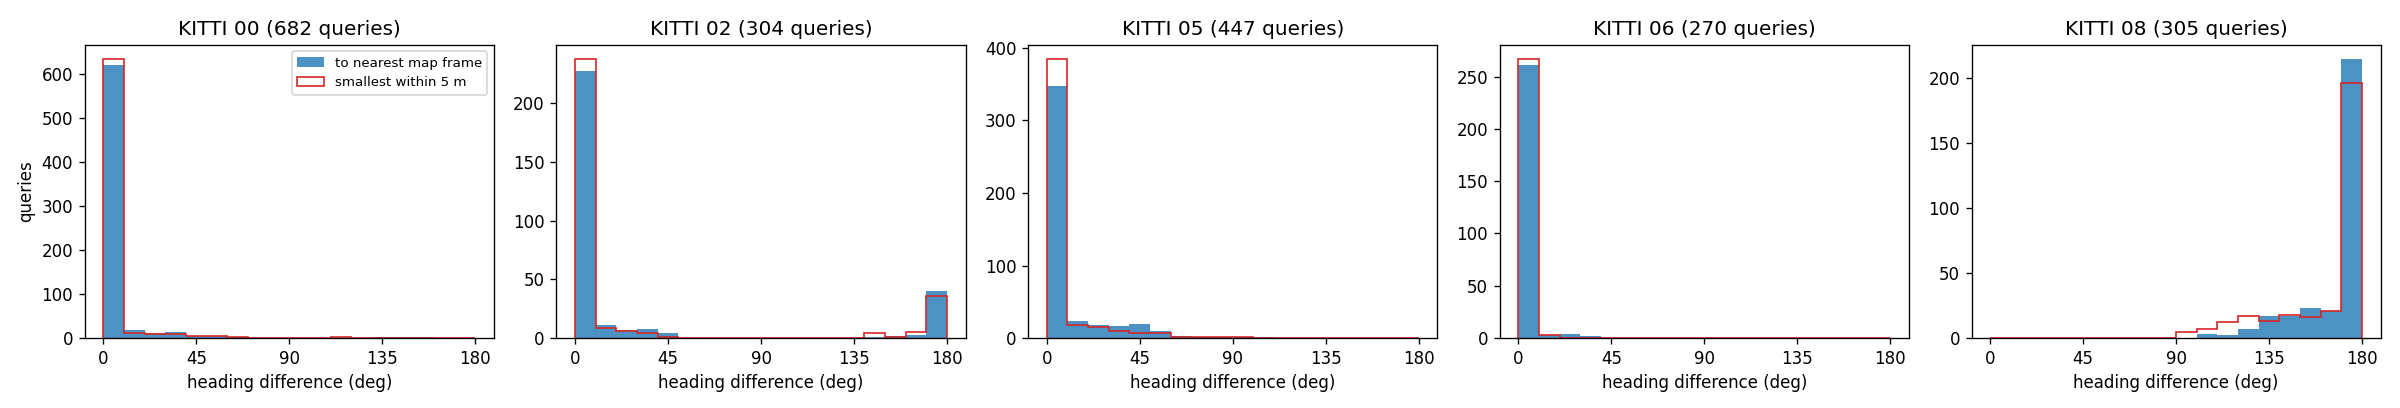

compass | 2026-10-08_without_Rein_b14094 | epoch_20
  00: evaluating 6 compass errors
  02: evaluating 6 compass errors
  05: evaluating 6 compass errors
  06: evaluating 6 compass errors
  08: evaluating 6 compass errors
  -> /content/drive/MyDrive/lpr/runs/bev/2026-10-08_without_Rein_b14094/eval/compass/epoch_20 
 sigma_deg seq    R@1    R@5   R@1%  queries  median_diff_nearest_deg  median_diff_min_deg  % same (<45)  R@1 same (<45)  % crossing (45-135)  R@1 crossing (45-135)  % opposite (>135)  R@1 opposite (>135)
         0  00  99.85 100.00 100.00      682                      1.0                  0.3          97.8           100.0                  1.5                   90.0                0.7                100.0
         0  02  98.68  99.67 100.00      304                      0.5                  0.2          84.2            99.6                  0.7                    0.0               15.1                 97.8
         0  05  97.54  98.43  98.66      447                      0.

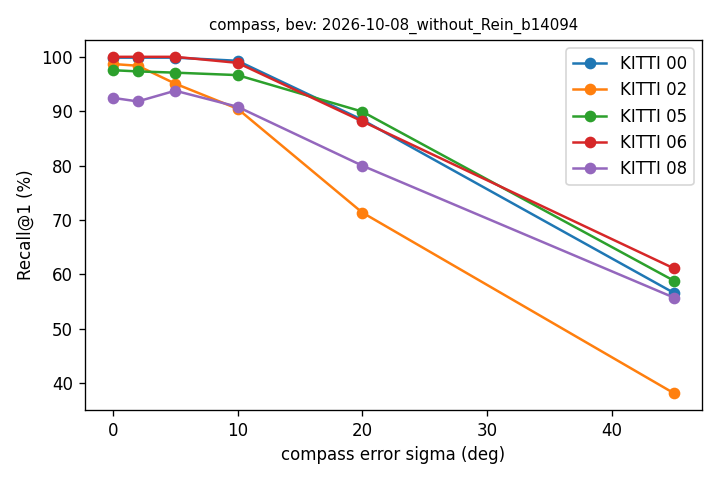

seqs_heading | official_2026-10-05_baseline_7711ab | model_best
  already done -> /content/drive/MyDrive/lpr/runs/bev/official_2026-10-05_baseline_7711ab/eval/seqs_heading/model_best
seq    R@1    R@5   R@1%  queries  median_diff_nearest_deg  median_diff_min_deg  % same (<45)  R@1 same (<45)  % crossing (45-135)  R@1 crossing (45-135)  % opposite (>135)  R@1 opposite (>135)
 00 100.00 100.00 100.00      682                      1.0                  0.3          97.8           100.0                  1.5                  100.0                0.7                100.0
 02  99.01 100.00 100.00      304                      0.5                  0.2          84.2            99.6                  0.7                   50.0               15.1                 97.8
 05  97.54  98.43  98.66      447                      0.8                  0.2          93.3            99.0                  6.7                   76.7                0.0                  NaN
 06 100.00 100.00 100.00      270        

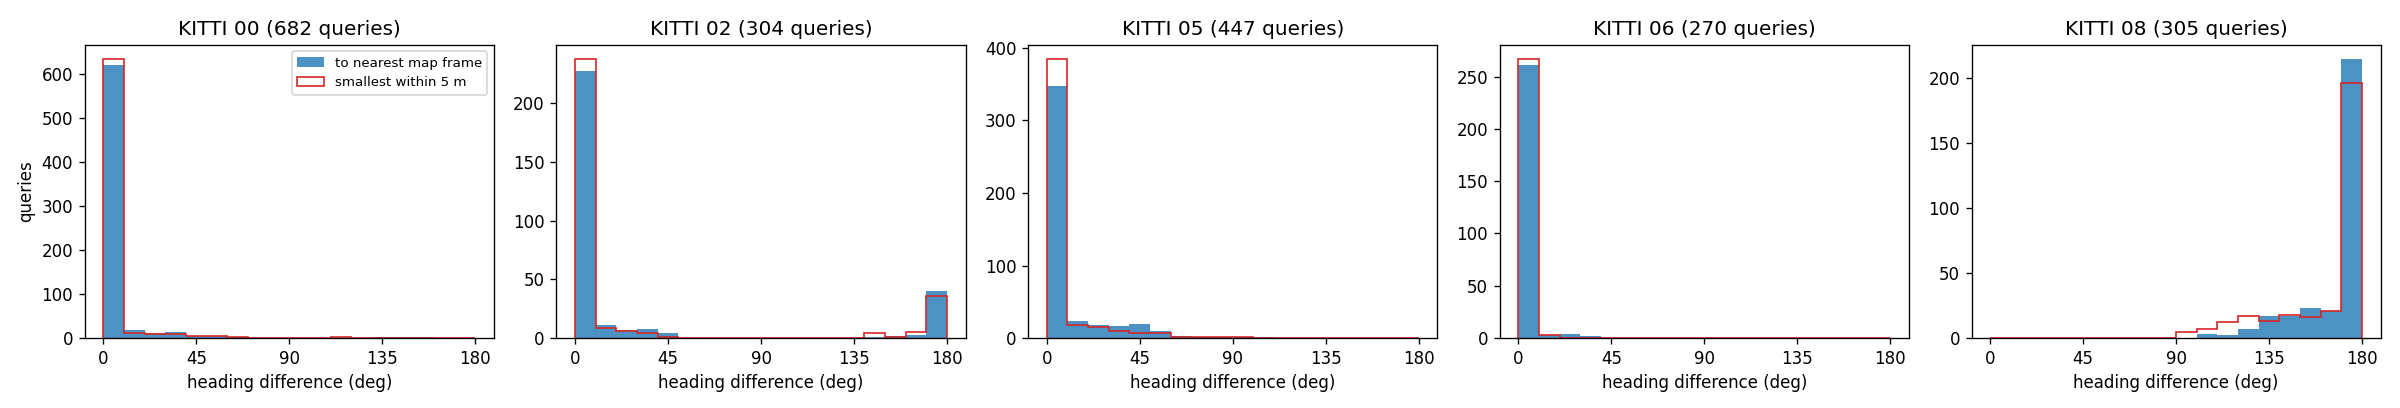

compass | official_2026-10-05_baseline_7711ab | model_best
  00: evaluating 6 compass errors
  02: evaluating 6 compass errors
  05: evaluating 6 compass errors
  06: evaluating 6 compass errors
  08: evaluating 6 compass errors
  -> /content/drive/MyDrive/lpr/runs/bev/official_2026-10-05_baseline_7711ab/eval/compass/model_best 
 sigma_deg seq    R@1    R@5   R@1%  queries  median_diff_nearest_deg  median_diff_min_deg  % same (<45)  R@1 same (<45)  % crossing (45-135)  R@1 crossing (45-135)  % opposite (>135)  R@1 opposite (>135)
         0  00  99.85 100.00 100.00      682                      1.0                  0.3          97.8           100.0                  1.5                   90.0                0.7                100.0
         0  02  98.68  99.34 100.00      304                      0.5                  0.2          84.2            99.2                  0.7                   50.0               15.1                 97.8
         0  05  97.54  98.43  98.66      447          

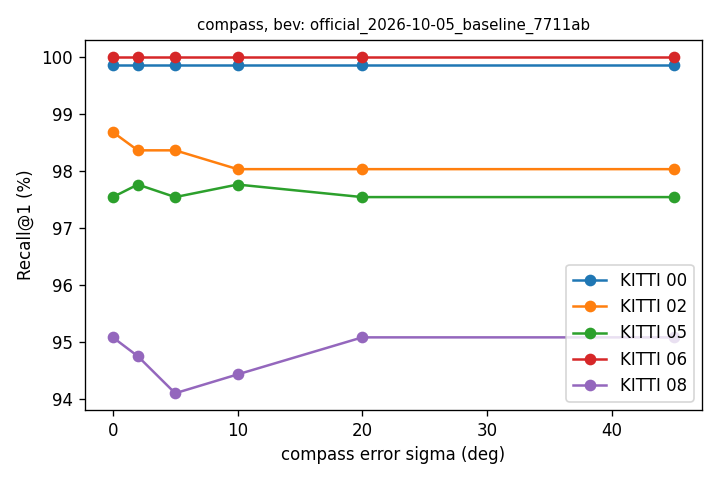

In [8]:
import pandas as pd
from IPython.display import Image, display

def run_evals(method, run_dir, ckpt, data_dir):
    """Every type in EVALS on one checkpoint; results in <run_dir>/eval/<type>/<checkpoint>/."""
    for e in EVALS:
        if method not in ev.EVAL_TYPES[e]["methods"]:
            continue
        res = subprocess.run(["python", "scripts/evaluate.py", "--method", method, "--run_dir", run_dir,
                              "--ckpt", ckpt, "--eval_type", e, "--data_dir", data_dir, "--kitti_root", KITTI],
                             capture_output=True, text=True, cwd="/content/lpr")
        print(res.stdout if res.returncode == 0 else res.stdout[-2000:] + res.stderr[-3000:])
        if res.returncode == 0:
            out = ev.eval_dir(run_dir, e, ev.resolve_ckpt(run_dir, ckpt))
            for png in sorted(glob.glob(f"{out}/*.png")):
                display(Image(png))

OFFICIAL_CKPT = "/content/lpr/third_party/BEVPlace2/runs/Aug08_10-17-29/model_best.pth.tar"
OFF_DIR = f"{DRIVE}/runs/bev/official_{VARIANT}"
if MODE == "smoke":
    print("skipped (MODE = smoke)")
else:
    if glob.glob(f"{RUN_DIR}/epoch_*.pth"):
        run_evals("bev", RUN_DIR, EVAL_CKPT, BEV)
    else:
        print("no checkpoint in", RUN_DIR)
    if EVAL_OFFICIAL:
        if not os.path.exists(f"{OFF_DIR}/config.json"):
            os.makedirs(OFF_DIR, exist_ok=True)
            ex.write_json(f"{OFF_DIR}/config.json", {"run": os.path.basename(OFF_DIR), "method": "bev",
                          "bev_variant": VARIANT, "status": "finished",
                          "params": {"source": "official checkpoint Aug08_10-17-29/model_best.pth.tar"}})
        run_evals("bev", OFF_DIR, OFFICIAL_CKPT, BEV)

## 8. Tables of all runs and evaluations, training curves

,method,run,status,variant,gpu,started,commit,lr,epochs,negatives,...,eval_02_R@1%,eval_05_R@1,eval_05_R@1%,eval_06_R@1,eval_06_R@1%,eval_08_R@1,eval_08_R@1%,pre_voxel,pre_res,pre_max_count
0,ndt,2026-10-04_baseline_4ed638,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-04,63d57d2,0.00001,20.0,18.0,...,83.55,89.49,91.28,98.52,100.00,4.26,6.89,NaN,NaN,NaN
1,ndt,2026-10-06_cov_transform_5c90e2,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-06T07:42:29,25fb722,0.00001,20.0,18.0,...,82.89,89.93,93.06,98.89,99.63,5.25,10.82,NaN,NaN,NaN
2,ndt,2026-10-07_f60015,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-07T15:20:26,101156f,0.00001,20.0,18.0,...,97.37,92.17,95.97,100.00,100.00,55.74,86.23,NaN,NaN,NaN
3,bev,2026-10-05_baseline_4ac7d1,running,2026-10-05_baseline_7711ab,Tesla T4,2026-10-05T18:13:10,d2c8f71,0.00010,20.0,10.0,...,100.00,98.43,99.55,100.00,100.00,91.15,99.34,0.4,0.4,10.0
4,bev,2026-10-08_without_Rein_b14094,finished,2026-10-05_baseline_7711ab,Tesla T4,2026-10-08T08:50:15,af592a7,0.00010,20.0,10.0,...,83.22,90.83,93.51,98.15,100.00,1.31,9.84,0.4,0.4,10.0
5,bev,official_2026-10-05_baseline_7711ab,finished,2026-10-05_baseline_7711ab,NaN,NaN,NaN,NaN,NaN,NaN,...,100.00,97.54,98.66,100.00,100.00,94.10,99.67,0.4,0.4,10.0


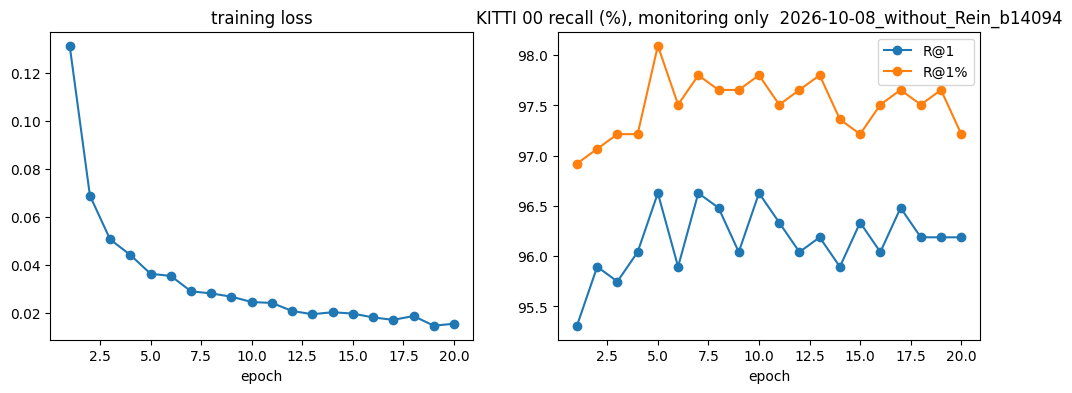

In [9]:
import matplotlib.pyplot as plt
!python scripts/summarize_runs.py --drive {DRIVE} > /dev/null
display(pd.read_csv(f"{DRIVE}/runs_summary.csv", dtype={"run": str}))
if os.path.exists(f"{RUN_DIR}/metrics.csv"):
    m = pd.read_csv(f"{RUN_DIR}/metrics.csv").drop_duplicates("epoch", keep="last")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(m.epoch, m.train_loss, marker="o"); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
    if "R@1" in m:
        ax[1].plot(m.epoch, m["R@1"], marker="o", label="R@1"); ax[1].plot(m.epoch, m["R@1%"], marker="o", label="R@1%")
    ax[1].set_title(f"KITTI {SEQ} recall (%), monitoring only  {RUN}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()

## 9. NDT-Transformer vs BEVPlace++ (every run with a `seqs_heading` evaluation)

In [10]:
p = f"{DRIVE}/evals_summary.csv"
if os.path.exists(p):
    e = pd.read_csv(p, dtype={"seq": str, "run": str, "checkpoint": str})
    sh = e[e.eval_type == "seqs_heading"]
    print("Recall@1 per sequence")
    display(sh.pivot_table(index=["method", "run", "checkpoint"], columns="seq", values="R@1"))
    cols = [c for c in sh.columns if c.startswith("R@1 ")]
    for s in ("02", "08"):
        print(f"KITTI {s}: Recall@1 per heading group (share of queries in the % columns)")
        g = sh[sh.seq == s].set_index(["method", "run", "checkpoint"])
        display(g[[c for c in g.columns if c.startswith("% ")] + cols])
    cp = e[e.eval_type == "compass"]
    if len(cp):
        print("Compass: Recall@1 per sequence (columns) and compass error sigma in degrees (rows)")
        display(cp.pivot_table(index=["method", "run", "checkpoint", "sigma_deg"], columns="seq", values="R@1"))
    tn = e[e.eval_type == "tnet"]
    if len(tn):
        print("T-Net check (scans rotated by 'angle')")
        display(tn.dropna(axis=1, how="all").set_index(["run", "checkpoint", "angle"])
                .drop(columns=["method", "eval_type", "complete", "seq"], errors="ignore"))

Recall@1 per sequence


seq                                                        00     02     05  \
method run                                 checkpoint                         
bev    2026-10-05_baseline_4ac7d1          epoch_18     99.85  99.34  98.43   
       2026-10-08_without_Rein_b14094      epoch_20     96.19  80.26  90.83   
       official_2026-10-05_baseline_7711ab model_best  100.00  99.01  97.54   
ndt    2026-10-04_baseline_4ed638          epoch_20     95.31  80.26  89.49   
       2026-10-06_cov_transform_5c90e2     epoch_20     95.45  80.59  89.93   
       2026-10-07_f60015                   epoch_20     97.36  85.53  92.17   

seq                                                        06     08  
method run                                 checkpoint                 
bev    2026-10-05_baseline_4ac7d1          epoch_18    100.00  91.15  
       2026-10-08_without_Rein_b14094      epoch_20     98.15   1.31  
       official_2026-10-05_baseline_7711ab model_best  100.00  94.10  
ndt    2026-10-04_baseline_4ed638          epoch_20     98.52   4.26  
       2026-10-06_cov_transform_5c90e2     epoch_20     98.89   5.25  
       2026-10-07_f60015                   epoch_20    100.00  55.74

KITTI 02: Recall@1 per heading group (share of queries in the % columns)


% same (<45)  \
method run                                 checkpoint                 
ndt    2026-10-04_baseline_4ed638          epoch_20            84.2   
       2026-10-06_cov_transform_5c90e2     epoch_20            84.2   
       2026-10-07_f60015                   epoch_20            84.2   
bev    2026-10-05_baseline_4ac7d1          epoch_18            84.2   
       2026-10-08_without_Rein_b14094      epoch_20            84.2   
       official_2026-10-05_baseline_7711ab model_best          84.2   

                                                       % crossing (45-135)  \
method run                                 checkpoint                        
ndt    2026-10-04_baseline_4ed638          epoch_20                    0.7   
       2026-10-06_cov_transform_5c90e2     epoch_20                    0.7   
       2026-10-07_f60015                   epoch_20                    0.7   
bev    2026-10-05_baseline_4ac7d1          epoch_18                    0.7   
       2026-10-08_without_Rein_b14094      epoch_20                    0.7   
       official_2026-10-05_baseline_7711ab model_best                  0.7   

                                                       % opposite (>135)  \
method run                                 checkpoint                      
ndt    2026-10-04_baseline_4ed638          epoch_20                 15.1   
       2026-10-06_cov_transform_5c90e2     epoch_20                 15.1   
       2026-10-07_f60015                   epoch_20                 15.1   
bev    2026-10-05_baseline_4ac7d1          epoch_18                 15.1   
       2026-10-08_without_Rein_b14094      epoch_20                 15.1   
       official_2026-10-05_baseline_7711ab model_best               15.1   

                                                       R@1 same (<45)  \
method run                                 checkpoint                   
ndt    2026-10-04_baseline_4ed638          epoch_20              95.3   
       2026-10-06_cov_transform_5c90e2     epoch_20              95.7   
       2026-10-07_f60015                   epoch_20              96.9   
bev    2026-10-05_baseline_4ac7d1          epoch_18              99.6   
       2026-10-08_without_Rein_b14094      epoch_20              95.3   
       official_2026-10-05_baseline_7711ab model_best            99.6   

                                                       R@1 crossing (45-135)  \
method run                                 checkpoint                          
ndt    2026-10-04_baseline_4ed638          epoch_20                      0.0   
       2026-10-06_cov_transform_5c90e2     epoch_20                      0.0   
       2026-10-07_f60015                   epoch_20                      0.0   
bev    2026-10-05_baseline_4ac7d1          epoch_18                    100.0   
       2026-10-08_without_Rein_b14094      epoch_20                      0.0   
       official_2026-10-05_baseline_7711ab model_best                   50.0   

                                                       R@1 opposite (>135)  
method run                                 checkpoint                       
ndt    2026-10-04_baseline_4ed638          epoch_20                    0.0  
       2026-10-06_cov_transform_5c90e2     epoch_20                    0.0  
       2026-10-07_f60015                   epoch_20                   26.1  
bev    2026-10-05_baseline_4ac7d1          epoch_18                   97.8  
       2026-10-08_without_Rein_b14094      epoch_20                    0.0  
       official_2026-10-05_baseline_7711ab model_best                 97.8

KITTI 08: Recall@1 per heading group (share of queries in the % columns)


% same (<45)  \
method run                                 checkpoint                 
ndt    2026-10-04_baseline_4ed638          epoch_20             0.0   
       2026-10-06_cov_transform_5c90e2     epoch_20             0.0   
       2026-10-07_f60015                   epoch_20             0.0   
bev    2026-10-05_baseline_4ac7d1          epoch_18             0.0   
       2026-10-08_without_Rein_b14094      epoch_20             0.0   
       official_2026-10-05_baseline_7711ab model_best           0.0   

                                                       % crossing (45-135)  \
method run                                 checkpoint                        
ndt    2026-10-04_baseline_4ed638          epoch_20                    6.6   
       2026-10-06_cov_transform_5c90e2     epoch_20                    6.6   
       2026-10-07_f60015                   epoch_20                    6.6   
bev    2026-10-05_baseline_4ac7d1          epoch_18                    6.6   
       2026-10-08_without_Rein_b14094      epoch_20                    6.6   
       official_2026-10-05_baseline_7711ab model_best                  6.6   

                                                       % opposite (>135)  \
method run                                 checkpoint                      
ndt    2026-10-04_baseline_4ed638          epoch_20                 93.4   
       2026-10-06_cov_transform_5c90e2     epoch_20                 93.4   
       2026-10-07_f60015                   epoch_20                 93.4   
bev    2026-10-05_baseline_4ac7d1          epoch_18                 93.4   
       2026-10-08_without_Rein_b14094      epoch_20                 93.4   
       official_2026-10-05_baseline_7711ab model_best               93.4   

                                                       R@1 same (<45)  \
method run                                 checkpoint                   
ndt    2026-10-04_baseline_4ed638          epoch_20               NaN   
       2026-10-06_cov_transform_5c90e2     epoch_20               NaN   
       2026-10-07_f60015                   epoch_20               NaN   
bev    2026-10-05_baseline_4ac7d1          epoch_18               NaN   
       2026-10-08_without_Rein_b14094      epoch_20               NaN   
       official_2026-10-05_baseline_7711ab model_best             NaN   

                                                       R@1 crossing (45-135)  \
method run                                 checkpoint                          
ndt    2026-10-04_baseline_4ed638          epoch_20                      0.0   
       2026-10-06_cov_transform_5c90e2     epoch_20                      0.0   
       2026-10-07_f60015                   epoch_20                     35.0   
bev    2026-10-05_baseline_4ac7d1          epoch_18                     65.0   
       2026-10-08_without_Rein_b14094      epoch_20                      0.0   
       official_2026-10-05_baseline_7711ab model_best                   75.0   

                                                       R@1 opposite (>135)  
method run                                 checkpoint                       
ndt    2026-10-04_baseline_4ed638          epoch_20                    4.6  
       2026-10-06_cov_transform_5c90e2     epoch_20                    5.6  
       2026-10-07_f60015                   epoch_20                   57.2  
bev    2026-10-05_baseline_4ac7d1          epoch_18                   93.0  
       2026-10-08_without_Rein_b14094      epoch_20                    1.4  
       official_2026-10-05_baseline_7711ab model_best                 95.4

Compass: Recall@1 per sequence (columns) and compass error sigma in degrees (rows)


seq                                                                 00     02  \
method run                                 checkpoint sigma_deg                 
bev    2026-10-08_without_Rein_b14094      epoch_20   0.0        99.85  98.68   
                                                      2.0        99.85  98.36   
                                                      5.0        99.85  95.07   
                                                      10.0       99.27  90.46   
                                                      20.0       88.42  71.38   
                                                      45.0       56.60  38.16   
       official_2026-10-05_baseline_7711ab model_best 0.0        99.85  98.68   
                                                      2.0        99.85  98.36   
                                                      5.0        99.85  98.36   
                                                      10.0       99.85  98.03   
                                                      20.0       99.85  98.03   
                                                      45.0       99.85  98.03   
ndt    2026-10-06_cov_transform_5c90e2     epoch_20   0.0        98.68  93.42   
                                                      2.0        98.97  93.42   
                                                      5.0        98.68  88.16   
                                                      10.0       95.31  77.96   
                                                      20.0       75.07  54.93   
                                                      45.0       43.55  31.25   
       2026-10-07_f60015                   epoch_20   0.0        98.24  91.78   
                                                      2.0        98.39  91.45   
                                                      5.0        98.09  91.78   
                                                      10.0       98.09  91.78   
                                                      20.0       97.95  88.82   
                                                      45.0       96.92  82.57   

seq                                                                 05  \
method run                                 checkpoint sigma_deg          
bev    2026-10-08_without_Rein_b14094      epoch_20   0.0        97.54   
                                                      2.0        97.32   
                                                      5.0        97.09   
                                                      10.0       96.64   
                                                      20.0       89.93   
                                                      45.0       58.84   
       official_2026-10-05_baseline_7711ab model_best 0.0        97.54   
                                                      2.0        97.76   
                                                      5.0        97.54   
                                                      10.0       97.76   
                                                      20.0       97.54   
                                                      45.0       97.54   
ndt    2026-10-06_cov_transform_5c90e2     epoch_20   0.0        95.08   
                                                      2.0        94.85   
                                                      5.0        94.85   
                                                      10.0       90.60   
                                                      20.0       76.06   
                                                      45.0       43.85   
       2026-10-07_f60015                   epoch_20   0.0        92.84   
                                                      2.0        92.84   
                                                      5.0        92.84   
                                                      10.0       92.62   
                                                      20.0       92.39   
                                           

T-Net check (scans rotated by 'angle')


T_dev_I   T_det  T_static  \
run                             checkpoint angle                              
2026-10-06_cov_transform_5c90e2 epoch_20   0.0     1.2533  3.2437    0.0000   
                                           15.0    1.2523  3.2416    0.0031   
                                           30.0    1.2462  3.2277    0.0072   
                                           45.0    1.2375  3.2077    0.0105   
                                           60.0    1.2307  3.1919    0.0118   
                                           90.0    1.2224  3.1724    0.0124   
                                           120.0   1.2386  3.2105    0.0123   
                                           150.0   1.2553  3.2490    0.0077   
                                           180.0   1.2555  3.2488    0.0048   
2026-10-07_f60015               epoch_20   0.0     1.9174  1.0655    0.0000   
                                           15.0    1.9174  1.0655    0.0007   
                                           30.0    1.9163  1.0658    0.0012   
                                           45.0    1.9150  1.0663    0.0016   
                                           60.0    1.9150  1.0663    0.0017   
                                           90.0    1.9156  1.0662    0.0016   
                                           120.0   1.9136  1.0669    0.0017   
                                           150.0   1.9158  1.0661    0.0015   
                                           180.0   1.9165  1.0658    0.0019   

                                                  T_follow  T_yaw_deg  \
run                             checkpoint angle                        
2026-10-06_cov_transform_5c90e2 epoch_20   0.0      0.0000     0.0000   
                                           15.0     0.1649     0.0000   
                                           30.0     0.3268    -0.0003   
                                           45.0     0.4829    -0.0007   
                                           60.0     0.6305    -0.0010   
                                           90.0     0.8911    -0.0012   
                                           120.0    1.0926    -0.0009   
                                           150.0    1.2202    -0.0003   
                                           180.0    1.2633    -0.0000   
2026-10-07_f60015               epoch_20   0.0      0.0000    -0.0000   
                                           15.0     0.0764     0.0002   
                                           30.0     0.1515     0.0027   
                                           45.0     0.2240     0.0065   
                                           60.0     0.2927     0.0073   
                                           90.0     0.4139     0.0036   
                                           120.0    0.5071     0.0087   
                                           150.0    0.5654     0.0051   
                                           180.0    0.5853     0.0011   

                                                  desc_drift  self_top1  
run                             checkpoint angle                         
2026-10-06_cov_transform_5c90e2 epoch_20   0.0        0.0000      1.000  
                                           15.0       0.3660      1.000  
                                           30.0       0.6210      0.425  
                                           45.0       0.7635      0.065  
                                           60.0       0.8364      0.030  
                                           90.0       0.9088      0.020  
                                           120.0      0.9399      0.015  
                                           150.0      0.9343      0.005  
                                           180.0      0.9280      0.025  
2026-10-07_f60015               epoch_20   0.0        0.0000      1.000  
                                           15.0       0.1048      1.000  
                                           30.